In [1]:
import torch
import torch.nn as nn # neural networks
from torch.optim import Adam # optimizer
from torch.utils.data import Dataset, DataLoader
from torchsummary import summary # model summary
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

device = 'cuda' if torch.cuda.is_available() else 'cpu' # check if GPU is available
print(f'Using {device} device')

Using cuda device


## Data

In [2]:
data_df = pd.read_csv('../data/rice-type-classification/riceClassification.csv') # load dataset
data_df.head()

,id,Area,MajorAxisLength,MinorAxisLength,Eccentricity,ConvexArea,EquivDiameter,Extent,Perimeter,Roundness,AspectRation,Class
0,1,4537,92.229316,64.012769,0.719916,4677,76.004525,0.657536,273.085,0.764510,1.440796,1
1,2,2872,74.691881,51.400454,0.725553,3015,60.471018,0.713009,208.317,0.831658,1.453137,1
2,3,3048,76.293164,52.043491,0.731211,3132,62.296341,0.759153,210.012,0.868434,1.465950,1
3,4,3073,77.033628,51.928487,0.738639,3157,62.551300,0.783529,210.657,0.870203,1.483456,1
4,5,3693,85.124785,56.374021,0.749282,3802,68.571668,0.769375,230.332,0.874743,1.510000,1


The purpose of this project is not to really implement a best practice or complex preprocessing. This project focuses on how to get familiar with PyTorch.

In [3]:
data_df.dropna(inplace=True) # drop rows with missing values
# inplace=True means that the changes will be made in the original dataframe and not a copy of it

In [4]:
data_df.drop('id', axis=1, inplace=True) # drop id column

In [5]:
data_df.info() # check for null values and data types

<class 'pandas.DataFrame'>
RangeIndex: 18185 entries, 0 to 18184
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Area             18185 non-null  int64  
 1   MajorAxisLength  18185 non-null  float64
 2   MinorAxisLength  18185 non-null  float64
 3   Eccentricity     18185 non-null  float64
 4   ConvexArea       18185 non-null  int64  
 5   EquivDiameter    18185 non-null  float64
 6   Extent           18185 non-null  float64
 7   Perimeter        18185 non-null  float64
 8   Roundness        18185 non-null  float64
 9   AspectRation     18185 non-null  float64
 10  Class            18185 non-null  int64  
dtypes: float64(8), int64(3)
memory usage: 1.5 MB


In [6]:
data_df.head()

,Area,MajorAxisLength,MinorAxisLength,Eccentricity,ConvexArea,EquivDiameter,Extent,Perimeter,Roundness,AspectRation,Class
0,4537,92.229316,64.012769,0.719916,4677,76.004525,0.657536,273.085,0.764510,1.440796,1
1,2872,74.691881,51.400454,0.725553,3015,60.471018,0.713009,208.317,0.831658,1.453137,1
2,3048,76.293164,52.043491,0.731211,3132,62.296341,0.759153,210.012,0.868434,1.465950,1
3,3073,77.033628,51.928487,0.738639,3157,62.551300,0.783529,210.657,0.870203,1.483456,1
4,3693,85.124785,56.374021,0.749282,3802,68.571668,0.769375,230.332,0.874743,1.510000,1


In [7]:
print(data_df['Class'].unique()) # check unique values in Class column

[1 0]


In [8]:
print(data_df['Class'].value_counts()) # check unique values in Class column

Class
1    9985
0    8200
Name: count, dtype: int64


In [9]:
original_df = data_df.copy() # create a copy of the original dataframe

for column in data_df.columns:
    data_df[column] = data_df[column]/data_df[column].abs().max() # normalize the data

data_df.head() # check the first 5 rows of the dataframe

,Area,MajorAxisLength,MinorAxisLength,Eccentricity,ConvexArea,EquivDiameter,Extent,Perimeter,Roundness,AspectRation,Class
0,0.444368,0.503404,0.775435,0.744658,0.424873,0.666610,0.741661,0.537029,0.844997,0.368316,1.0
1,0.281293,0.407681,0.622653,0.750489,0.273892,0.530370,0.804230,0.409661,0.919215,0.371471,1.0
2,0.298531,0.416421,0.630442,0.756341,0.284520,0.546380,0.856278,0.412994,0.959862,0.374747,1.0
3,0.300979,0.420463,0.629049,0.764024,0.286791,0.548616,0.883772,0.414262,0.961818,0.379222,1.0
4,0.361704,0.464626,0.682901,0.775033,0.345385,0.601418,0.867808,0.452954,0.966836,0.386007,1.0


In [10]:
X = np.array(data_df.iloc[:, :-1]) # features
Y = np.array(data_df.iloc[:, -1]) # target
# why array? because we need to convert the dataframe to numpy array for pytorch

In [11]:
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.3, random_state=42) # split the data into train and test sets
# split the data into train and test sets with 70% for training and 30% for testing. random_state=42 is used to ensure that the split is reproducible.

In [12]:
X_test, X_val, Y_test, Y_val = train_test_split(X_test, Y_test, test_size=0.5, random_state=42)
# split the test set into validation and test sets with 50% for validation and 50% for testing. random_state=42 is used to ensure that the split is reproducible.

In [13]:
print(X_train.shape, Y_train.shape) # check the shape of the train set
print(X_val.shape, Y_val.shape) # check the shape of the validation set
print(X_test.shape, Y_test.shape) # check the shape of the test set

(12729, 10) (12729,)
(2728, 10) (2728,)
(2728, 10) (2728,)


In [14]:
class dataset(Dataset):
    def __init__(self, X, Y):
        self.X = torch.tensor(X, dtype=torch.float32).to(device) # convert to tensor
        self.Y = torch.tensor(Y, dtype=torch.float32).to(device) # convert to tensor

    def __len__(self):
        return len(self.X)

    def __getitem__(self, index):
        return self.X[index], self.Y[index]

In [15]:
training_data = dataset(X_train, Y_train) # create training dataset
validation_data = dataset(X_val, Y_val) # create validation dataset
test_data = dataset(X_test, Y_test) # create test dataset

In [16]:
train_data_loader = DataLoader(training_data, batch_size=8, shuffle=True) # create training dataloader
validation_data_loader = DataLoader(validation_data, batch_size=8, shuffle=False) # create validation dataloader
testing_data_loader = DataLoader(test_data, batch_size=8, shuffle=False) # create test dataloader

In [17]:
for x, y in train_data_loader:
    print(x)
    print('========')
    print(y)
    break

tensor([[0.8982, 0.9023, 0.8657, 0.9327, 0.8505, 0.9478, 0.6168, 0.7681, 0.8350,
         0.5913],
        [0.7981, 0.8112, 0.8560, 0.9100, 0.7550, 0.8934, 0.7599, 0.7073, 0.8751,
         0.5376],
        [0.6088, 0.8709, 0.6214, 0.9795, 0.5811, 0.7803, 0.9106, 0.6998, 0.6819,
         0.7952],
        [0.6447, 0.9039, 0.6247, 0.9829, 0.6154, 0.8029, 0.5924, 0.7152, 0.6911,
         0.8209],
        [0.6585, 0.8272, 0.6906, 0.9584, 0.6216, 0.8115, 0.9379, 0.6828, 0.7746,
         0.6796],
        [0.8975, 0.8959, 0.8764, 0.9285, 0.8617, 0.9473, 0.7314, 0.7718, 0.8262,
         0.5799],
        [0.7466, 0.8004, 0.8127, 0.9198, 0.7047, 0.8641, 0.8790, 0.6873, 0.8668,
         0.5588],
        [0.4498, 0.7810, 0.5053, 0.9894, 0.4309, 0.6706, 0.7928, 0.6084, 0.6663,
         0.8769]], device='cuda:0')
tensor([0., 0., 1., 1., 1., 0., 0., 1.], device='cuda:0')


## Model

In [18]:
HIDDEN_NEURONS = 10 # number of neurons in the hidden layer
class MyModel(nn.Module):
    def __init__(self):
        super(MyModel, self).__init__()
        # Define your model architecture here

        self.input_layer = nn.Linear(X.shape[1], HIDDEN_NEURONS) # input layer
        self.linear = nn.Linear(HIDDEN_NEURONS, 1) # hidden layer
        self.sigmoid = nn.Sigmoid() # activation function

    def forward(self, x):
        # Define the forward pass of your model
        # How the data flows through the model

        x = self.input_layer(x)
        x = self.linear(x)
        x = self.sigmoid(x)
        return x

# Above is the model architecture. The model has an input layer, a hidden layer, and an output layer. The input layer takes in the features and passes them to the hidden layer. The hidden layer applies a linear transformation and passes the result to the output layer. The output layer applies a sigmoid activation function to produce a probability between 0 and 1.

In [19]:
model = MyModel().to(device) # create model and move it to device

In [20]:
print(x) # check the number of features in the input data

tensor([[0.8982, 0.9023, 0.8657, 0.9327, 0.8505, 0.9478, 0.6168, 0.7681, 0.8350,
         0.5913],
        [0.7981, 0.8112, 0.8560, 0.9100, 0.7550, 0.8934, 0.7599, 0.7073, 0.8751,
         0.5376],
        [0.6088, 0.8709, 0.6214, 0.9795, 0.5811, 0.7803, 0.9106, 0.6998, 0.6819,
         0.7952],
        [0.6447, 0.9039, 0.6247, 0.9829, 0.6154, 0.8029, 0.5924, 0.7152, 0.6911,
         0.8209],
        [0.6585, 0.8272, 0.6906, 0.9584, 0.6216, 0.8115, 0.9379, 0.6828, 0.7746,
         0.6796],
        [0.8975, 0.8959, 0.8764, 0.9285, 0.8617, 0.9473, 0.7314, 0.7718, 0.8262,
         0.5799],
        [0.7466, 0.8004, 0.8127, 0.9198, 0.7047, 0.8641, 0.8790, 0.6873, 0.8668,
         0.5588],
        [0.4498, 0.7810, 0.5053, 0.9894, 0.4309, 0.6706, 0.7928, 0.6084, 0.6663,
         0.8769]], device='cuda:0')


In [21]:
summary(model, input_size=(X.shape[1],)) # print model summary

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Linear-1                   [-1, 10]             110
            Linear-2                    [-1, 1]              11
           Sigmoid-3                    [-1, 1]               0
Total params: 121
Trainable params: 121
Non-trainable params: 0
----------------------------------------------------------------
Input size (MB): 0.00
Forward/backward pass size (MB): 0.00
Params size (MB): 0.00
Estimated Total Size (MB): 0.00
----------------------------------------------------------------


In [22]:
criterion = nn.BCELoss() # binary cross entropy loss
optimizer = Adam(model.parameters(), lr=0.001) # Adam optimizer with learning rate of 0.001

# 🧠 Understanding the Model from Zero (study notes)

> 📝 **Note:** The explanation in this cell was **written by Claude (AI)** at my request, because when I reached the model part I honestly had no background in it at all. All the **code** in this notebook is still typed by me while following the video.
>
> The numbers in these notes are **real**: they were calculated from this rice data, using one real batch of 8 grains from `training_data`. The model starts with random weights, so the numbers in my own model can be a bit different. That's normal.

---

## 0. Where are we?

```
✅ Data       already tensors, wrapped in a dataset, served by the DataLoader in batches
🔵 Model      the "brain" that guesses the rice type          ← explained here
🔵 Loss       a meter for "how wrong was the guess"           ← explained here
🔵 Optimizer  the "mechanic" that fixes the brain             ← explained here
⬜ Training   repeat: guess → measure the mistake → fix       ← next section
```

---

## 1. What is a model?

**A model is a guessing machine.** We put in **10 numbers** (the features of one grain of rice), and it gives back **1 number between 0 and 1**: how sure the model is that this grain is **class 1**.

```
[0.87, 0.84, 0.89, 0.91, 0.82, 0.93, 0.67, 0.73, 0.88, 0.53]  ──►  🧠 MODEL  ──►  0.52
           10 features of one grain of rice                                  "52% sure this is class 1"
```

When the model is first created, it's **still dumb** and just guesses randomly. **Training** is what makes it smart.

---

## 2. Neuron: the smallest "brain cell"

Imagine **one judge** scoring a grain of rice. The judge does 3 simple things:

1. **Multiplies** each feature by a **weight**: how important that feature is to this judge.
   - Big weight: the feature matters a lot.
   - Negative weight: "the bigger this feature is, the *less* likely the grain is class 1".
2. **Adds** all of those results together.
3. **Adds a bias**: the judge's "starting point" or default leaning.

That's it. **Just multiply and add**, like middle-school math. This one judge is called a **neuron**.

An example with only 3 features so it's easy to calculate. The features come from a real grain of rice (number 11049); the weights are made up so the math is friendly:

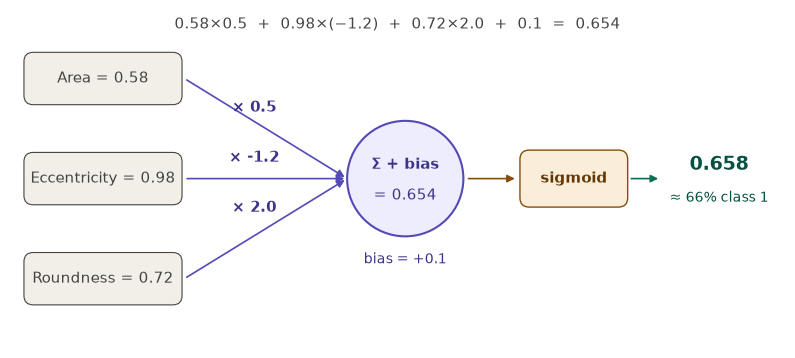

```
result = (0.58 × 0.5) + (0.98 × −1.2) + (0.72 × 2.0) + 0.1
       =   0.29       −   1.176       +   1.44       + 0.1
       =   0.654
```

The *sigmoid* box in the picture is explained in section 6. For now, just know that sigmoid turns `0.654` into `0.658`, which means "≈ 66% sure this is class 1".

---

## 3. Weights and bias = "parameters" = what the model learns

- **Weights and biases are all just numbers.** When the model is created, they are **filled with random values**.
- **They are the only thing the model learns.** "Learning" means **nudging these numbers a little at a time** until the guesses get better. (Remember `w.grad`? That's what tells us which way to nudge each number.)
- These numbers are called **parameters** (*params*). The `Param #` column in `summary` simply **counts these numbers**.

> 🎛️ **Analogy:** parameters are like **the knobs on a music mixer**. At first they're set randomly, so it sounds bad. Training = turning every knob a little at a time until it sounds good.

---

## 4. `nn.Linear`: a row of many neurons at once

We don't build neurons one by one. PyTorch has `nn.Linear(inputs, outputs)`, which means:

> "Make **`outputs`** neurons. Each neuron takes in **`inputs`** numbers."

Every neuron is connected to **all** of the incoming numbers, and every neuron has **its own** weights and bias.

| Code | Meaning | Counting the parameters |
|---|---|---|
| `nn.Linear(10, 10)` | 10 neurons, each one takes the 10 features | 10 neurons × (10 weights + 1 bias) = **110** |
| `nn.Linear(10, 1)` | 1 neuron that takes the 10 numbers from the previous layer | 1 neuron × (10 weights + 1 bias) = **11** |

Why is it called *Linear*? Because all it does is multiply and add. In math, that kind of calculation is called "linear" (if you draw it, you get a straight line).

---

## 5. Layers: input, hidden, output

If a neuron is a judge, then a **layer** is **one row of judges**. My model looks like this:

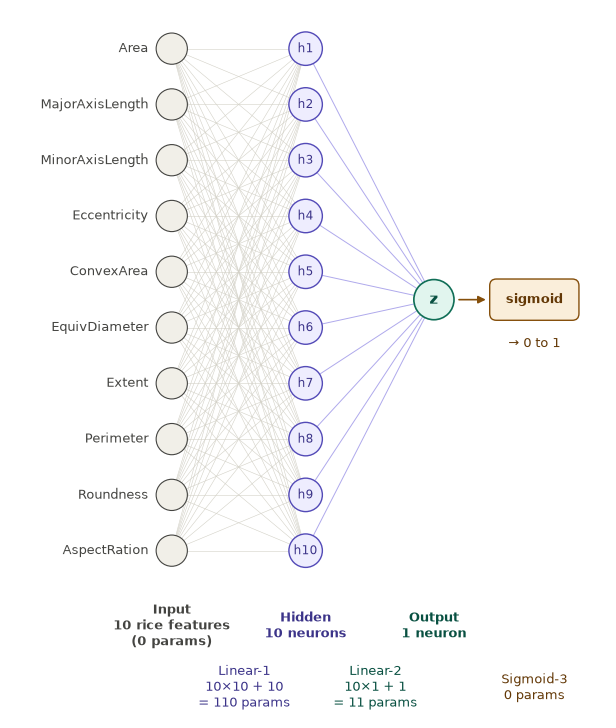

| Part | What it is | In my code | Params |
|---|---|---|---|
| **Input** | The 10 rice features. Just numbers coming in, **not** neurons | `x` | 0 |
| **Hidden** | 10 neurons (because `HIDDEN_NEURONS = 10`) | output of `self.input_layer` | **110** (Linear-1) |
| **Output** | 1 neuron that gives the final score | output of `self.linear` | **11** (Linear-2) |
| **Sigmoid** | Turns the final score into a number from 0 to 1 | `self.sigmoid` | 0 |

**Why "hidden"?** Because it sits in the middle and **we don't decide what it means**. The model decides on its own what each hidden neuron should "pay attention to". For example, `h3` might slowly learn to spot "long, thin rice". We never told it to.

**About the variable names in my code:** `self.input_layer` is really **the bridge from input to hidden**, and `self.linear` is **the bridge from hidden to output**. Variable names are free, you can call them anything. What decides the shape of the model are the numbers inside: `(10, 10)` and `(10, 1)`.

`HIDDEN_NEURONS = 10` is **our choice** (this kind of choice is called a *hyperparameter*). It could be 5, 32, or 64, and the number of params would change with it.

---

## 6. Sigmoid: the "squeezer" that turns any number into 0 to 1

**The problem:** the output neuron can give out any number, like `−3.7`, `0.65`, or `12`. But we want a **probability**, a number between 0 and 1.

**Sigmoid** is a fixed formula that "squeezes" any number into the range 0 to 1:

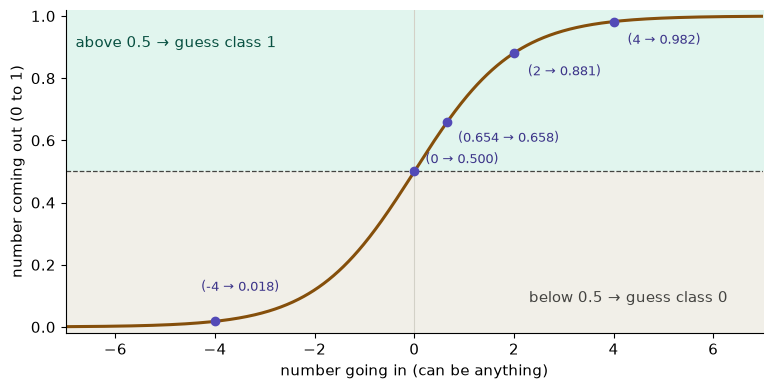

| Number going in | Out of sigmoid | What it means |
|---|---|---|
| −4 | 0.018 | Almost surely **class 0** |
| 0 | 0.500 | **Not sure**, 50:50 |
| 0.654 | 0.658 | Somewhat sure it's class 1 |
| 2 | 0.881 | Fairly sure it's class 1 |
| 4 | 0.982 | Almost surely **class 1** |

**The guessing rule:** if the result is **above 0.5**, guess **class 1**. If it's **below 0.5**, guess **class 0**.

Sigmoid has **0 params** because it's just a fixed formula. There are no knobs to turn, so there's nothing to learn.

---

## 7. Reading `class MyModel` line by line

The pattern is **very similar to `class dataset`** earlier in this notebook (and the little practice classes I wrote while learning about classes):

```python
class MyModel(nn.Module):                 # the model's blueprint, built on PyTorch's "official form" nn.Module
    def __init__(self):                   # runs ONCE when MyModel() is created → prepare the parts
        super(MyModel, self).__init__()   # first, switch on nn.Module's "built-in machinery"
        self.input_layer = nn.Linear(X.shape[1], HIDDEN_NEURONS)   # part 1: 10 → 10
        self.linear = nn.Linear(HIDDEN_NEURONS, 1)                 # part 2: 10 → 1
        self.sigmoid = nn.Sigmoid()                                # part 3: squeezer to 0–1

    def forward(self, x):                 # the ROUTE the data takes, top to bottom
        x = self.input_layer(x)
        x = self.linear(x)
        x = self.sigmoid(x)
        return x
```

| Part | In plain words |
|---|---|
| `class MyModel(nn.Module)` | The model's blueprint. `(nn.Module)` means it uses PyTorch's "official form", just like `dataset(Dataset)` |
| `super(...).__init__()` | "Switch on the built-in machinery first." Without this line, PyTorch can't **keep track of** the parts and their parameters, and you get an error |
| `self.input_layer = ...` | Stores a part inside the box, **just like `self.X = ...`** in `class dataset` |
| `X.shape[1]` | The number of columns in `X` (capital X = all the data) = **10** features |
| `__init__` vs `forward` | `__init__` = **build** the parts (only once). `forward` = **use** the parts (every time data comes in) |
| `model(x)` | PyTorch **automatically runs `forward(x)`**, just like `len(a)` automatically runs `__len__`. So we never call `forward` directly |
| `MyModel().to(device)` | Creates the model, then moves its **121 parameters to the GPU**. The data and the model **must be in the same place** (both on the GPU) |

---

## 8. Watching data flow through the model (real numbers!)

I took **one real batch of 8 grains from `training_data`** (grains number 9025, 3431, 5704, 10419, 10249, 2535, 3124, and 2940) and passed it through a model with exactly the same shape as mine:

```
x  (8 grains × 10 features)         shape [8, 10]
│
│  self.input_layer   (Linear-1: 10 → 10)
▼
h  (8 grains × 10 hidden neurons)   shape [8, 10]
   grain 1: [0.60, 0.81, −0.80, 0.35, 0.61, −0.21, −0.65, −0.10, −0.63, −0.34]
│
│  self.linear        (Linear-2: 10 → 1)
▼
z  (8 grains × 1 score)             shape [8, 1]
   [0.098, 0.107, 0.115, 0.090, 0.116, 0.124, 0.146, 0.183]
│
│  self.sigmoid
▼
p  (8 grains × 1 probability)       shape [8, 1]
   [0.524, 0.527, 0.529, 0.522, 0.529, 0.531, 0.536, 0.546]
```

- **The model's guesses** (above 0.5 = class 1): `[1, 1, 1, 1, 1, 1, 1, 1]`
- **The real answers:** `[0, 0, 0, 0, 0, 1, 1, 1]`
- Correct: **3 out of 8**. 😅

**That's expected!** The model **hasn't learned anything yet** because its weights are still random. All its guesses are around 0.5, which basically means: *"I don't know anything yet"*.

**Proof that a neuron is just multiply and add:** the first hidden neuron (`h1`) gives `0.6034` for grain 1. If I calculate it by hand (10 features × that neuron's 10 weights, add them up, then add the bias), I get **exactly the same: `0.6034`**. No magic inside. ✨

---

## 9. Reading the `summary(...)` output

```
        Layer (type)               Output Shape         Param #
================================================================
            Linear-1                   [-1, 10]             110
            Linear-2                    [-1, 1]              11
           Sigmoid-3                    [-1, 1]               0
================================================================
Total params: 121
Trainable params: 121
Non-trainable params: 0
```

| What it says | What it means |
|---|---|
| `Layer (type)` | The layer's name and its order (1, 2, 3) |
| `Output Shape [-1, 10]` | The shape of that layer's result. **`-1` means "however many grains are in the batch"** (8 in my DataLoader, but it could be 32 or anything). `10` = 10 numbers per grain |
| `Param #` | How many learnable numbers that layer has |
| `Total params: 121` | 110 + 11 + 0 = **121 knobs** |
| `Trainable: 121` | Every knob can be turned during training |
| `Non-trainable: 0` | No knobs are locked |
| `Params size (MB): 0.00` | 121 numbers × 4 bytes = **484 bytes**, so small it rounds down to 0.00 MB |

> 📏 **For comparison:** the BERT model in Project 05 has around **110 million** parameters. This rice model has only 121. 😄

---

## 10. Loss: measuring "how wrong"

```python
criterion = nn.BCELoss()
```

**BCE = Binary Cross Entropy.** *Binary* means 2 classes (0 or 1). Simply put, the loss gives a **"penalty score"**:

- The guess is **right and confident**: **small** penalty.
- The guess is **wrong but confident**: **very big** penalty.

Example when **the real answer is class 1**:

| Model's guess (p) | Loss (penalty) | Comment |
|---|---|---|
| 0.9 | 0.105 | Good, small penalty |
| 0.5 | 0.693 | A random 50:50 guess |
| 0.1 | 2.303 | Wrong and confident, big penalty |

(If the real answer is class 0, it's the other way around: guesses close to 0 get the small penalty.)

For the batch of 8 grains in section 8, the loss is **0.6997**, almost the same as the "random guess" level (0.693). **The goal of training: make this loss number smaller and smaller.**

---

## 11. Optimizer: the "mechanic" that fixes the model

```python
optimizer = Adam(model.parameters(), lr=0.001)
```

| Part | Meaning |
|---|---|
| `model.parameters()` | Hands the model's **121 knobs** to the mechanic |
| `Adam` | **The type of mechanic.** Adam is a popular method that's fairly smart about how big each step should be |
| `lr=0.001` | **Learning rate = the step size** each time a knob is turned |

> 📻 **Learning rate analogy:** like tuning an old radio by turning the dial.
> - Turn it **too much**: you keep jumping past the station and never land on it.
> - Turn it **too little**: it takes forever to get there.
> - `0.001` is a common "medium" step size.

---

## 12. Everything comes together in training (next section)

For **every batch** the DataLoader serves, these 4 steps happen (I'll type the actual code myself while watching the video):

```
① GUESS          the model looks at the batch          → a probability for every grain
② MEASURE        criterion compares the guesses        → 1 loss number, e.g. 0.6997
                 with the real answers
③ FIND DIRECTION loss.backward()                       → compute grad for all 121 parameters
④ FIX            the optimizer nudges all 121 knobs    → the model gets a little smarter
                 a little (by the size of lr)
   ↻ repeat for the next batch ... until every batch is done = 1 epoch
```

Each round only fixes things a tiny bit. But because it repeats **thousands of times**, the loss slowly goes down and the model's guesses get better. 📈

---

## 13. Mini dictionary

| Term | Simple meaning |
|---|---|
| **Neuron** | One "judge": multiply each feature by a weight, add them up, then add a bias |
| **Weight** | How important a feature is to a neuron |
| **Bias** | A neuron's default value or starting lean |
| **Parameter (params)** | All the weights and biases = the knobs turned while learning |
| **Layer** | One row of neurons |
| **`nn.Linear(a, b)`** | A layer with `b` neurons, each taking in `a` numbers |
| **Hidden layer** | A layer in the middle whose meaning the model decides on its own |
| **Sigmoid** | Squeezes any number into 0 to 1 (a probability) |
| **`forward`** | The route data takes inside the model |
| **`-1` in summary** | "However many grains are in the batch" |
| **Loss** | The penalty score: how wrong the model's guess is |
| **Optimizer** | The mechanic that turns the knobs so the loss goes down |
| **Learning rate (lr)** | The step size of each knob turn |
| **Hyperparameter** | A choice we make ourselves (batch size, `HIDDEN_NEURONS`, lr, epochs) |

---

## 14. Bonus (feel free to skip)

In this model, there's **no "bender"** between Linear-1 and Linear-2 (this is called an *activation function*, for example **ReLU**). Because of that, two Linear layers in a row are actually **no more powerful than a single Linear layer**: together they can still only draw a "straight line" to separate the classes. That's fine for this rice data, because the two types are fairly easy to tell apart, and the goal of this video is to learn how to write PyTorch. I'll meet **ReLU** in Project 02 (images), where this "bender" becomes important.

## Training